# Iris Flower Classification
**Oasis Infobyte SIP | Data Science Track | Task 1**

**Objective:** Train machine learning classifiers to predict the species of an iris flower (*Setosa*, *Versicolor* or *Virginica*) from its four physical measurements.

**Workflow:** Load data → EDA → Visualisation → Feature discussion → Train/test split → Train models → Evaluate → Pick the best model

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42  # fixed seed so results are reproducible

## 2. Load the Dataset
The Iris dataset ships with scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Replace numeric target (0/1/2) with readable species names
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")

# Shorter column names
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

### 3.1 Shape and data types

In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (150, 5)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


### 3.2 Null value check

In [4]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Total missing values: 0
Duplicate rows: 1


**Observation:** There are no missing values, so no imputation is needed. One duplicate row exists (two flowers with identical measurements). It is kept because identical measurements from different flowers are genuine data, and removing a single row of 150 would change nothing meaningful.

### 3.3 Descriptive statistics

In [5]:
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [6]:
# Class balance
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

**Observation:** Each of the three species has exactly 50 samples, so the classes are perfectly balanced. Accuracy is therefore a fair metric here.

### 3.4 Average measurements by species

In [7]:
df.groupby("species").mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


## 4. Visualisations

### 4.1 Pairplot: feature distributions by species

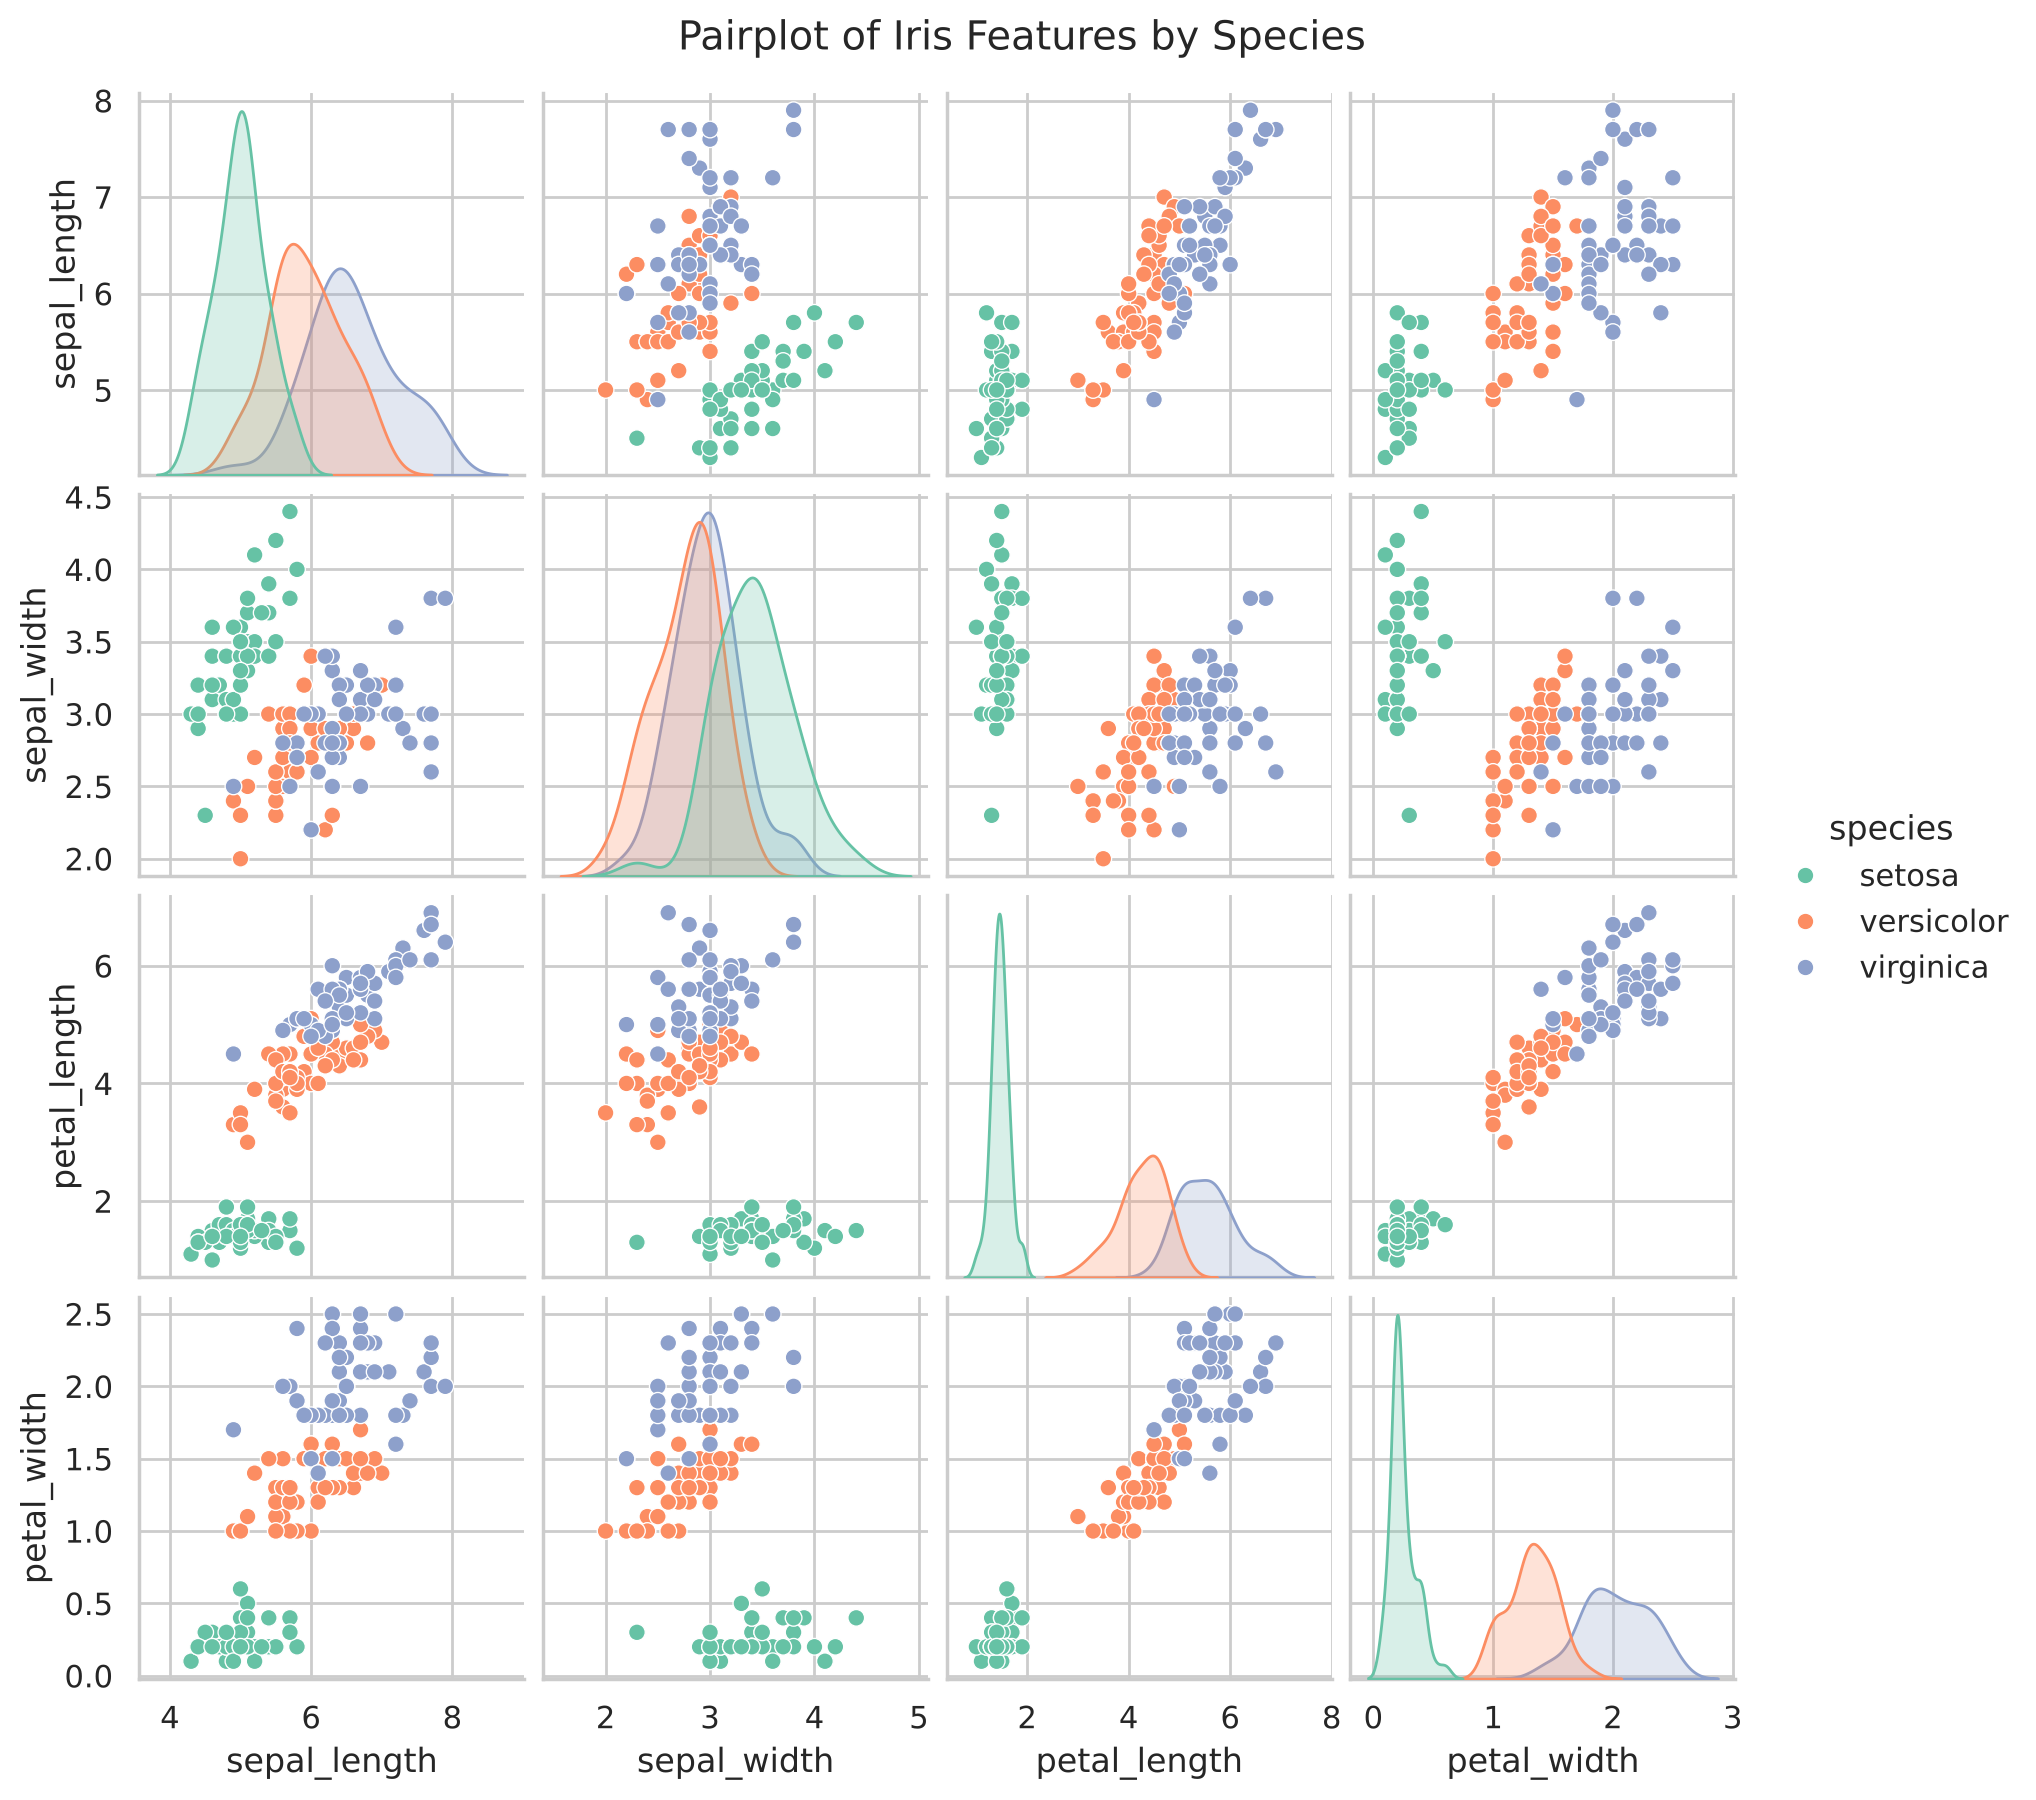

In [8]:
sns.pairplot(df, hue="species", diag_kind="kde", height=2.2)
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

**Observation:** *Setosa* (one cluster) separates cleanly from the other two in almost every plot. *Versicolor* and *Virginica* overlap a little, mostly in the sepal measurements. Petal measurements separate all three species much more clearly.

### 4.2 Box plots for each feature

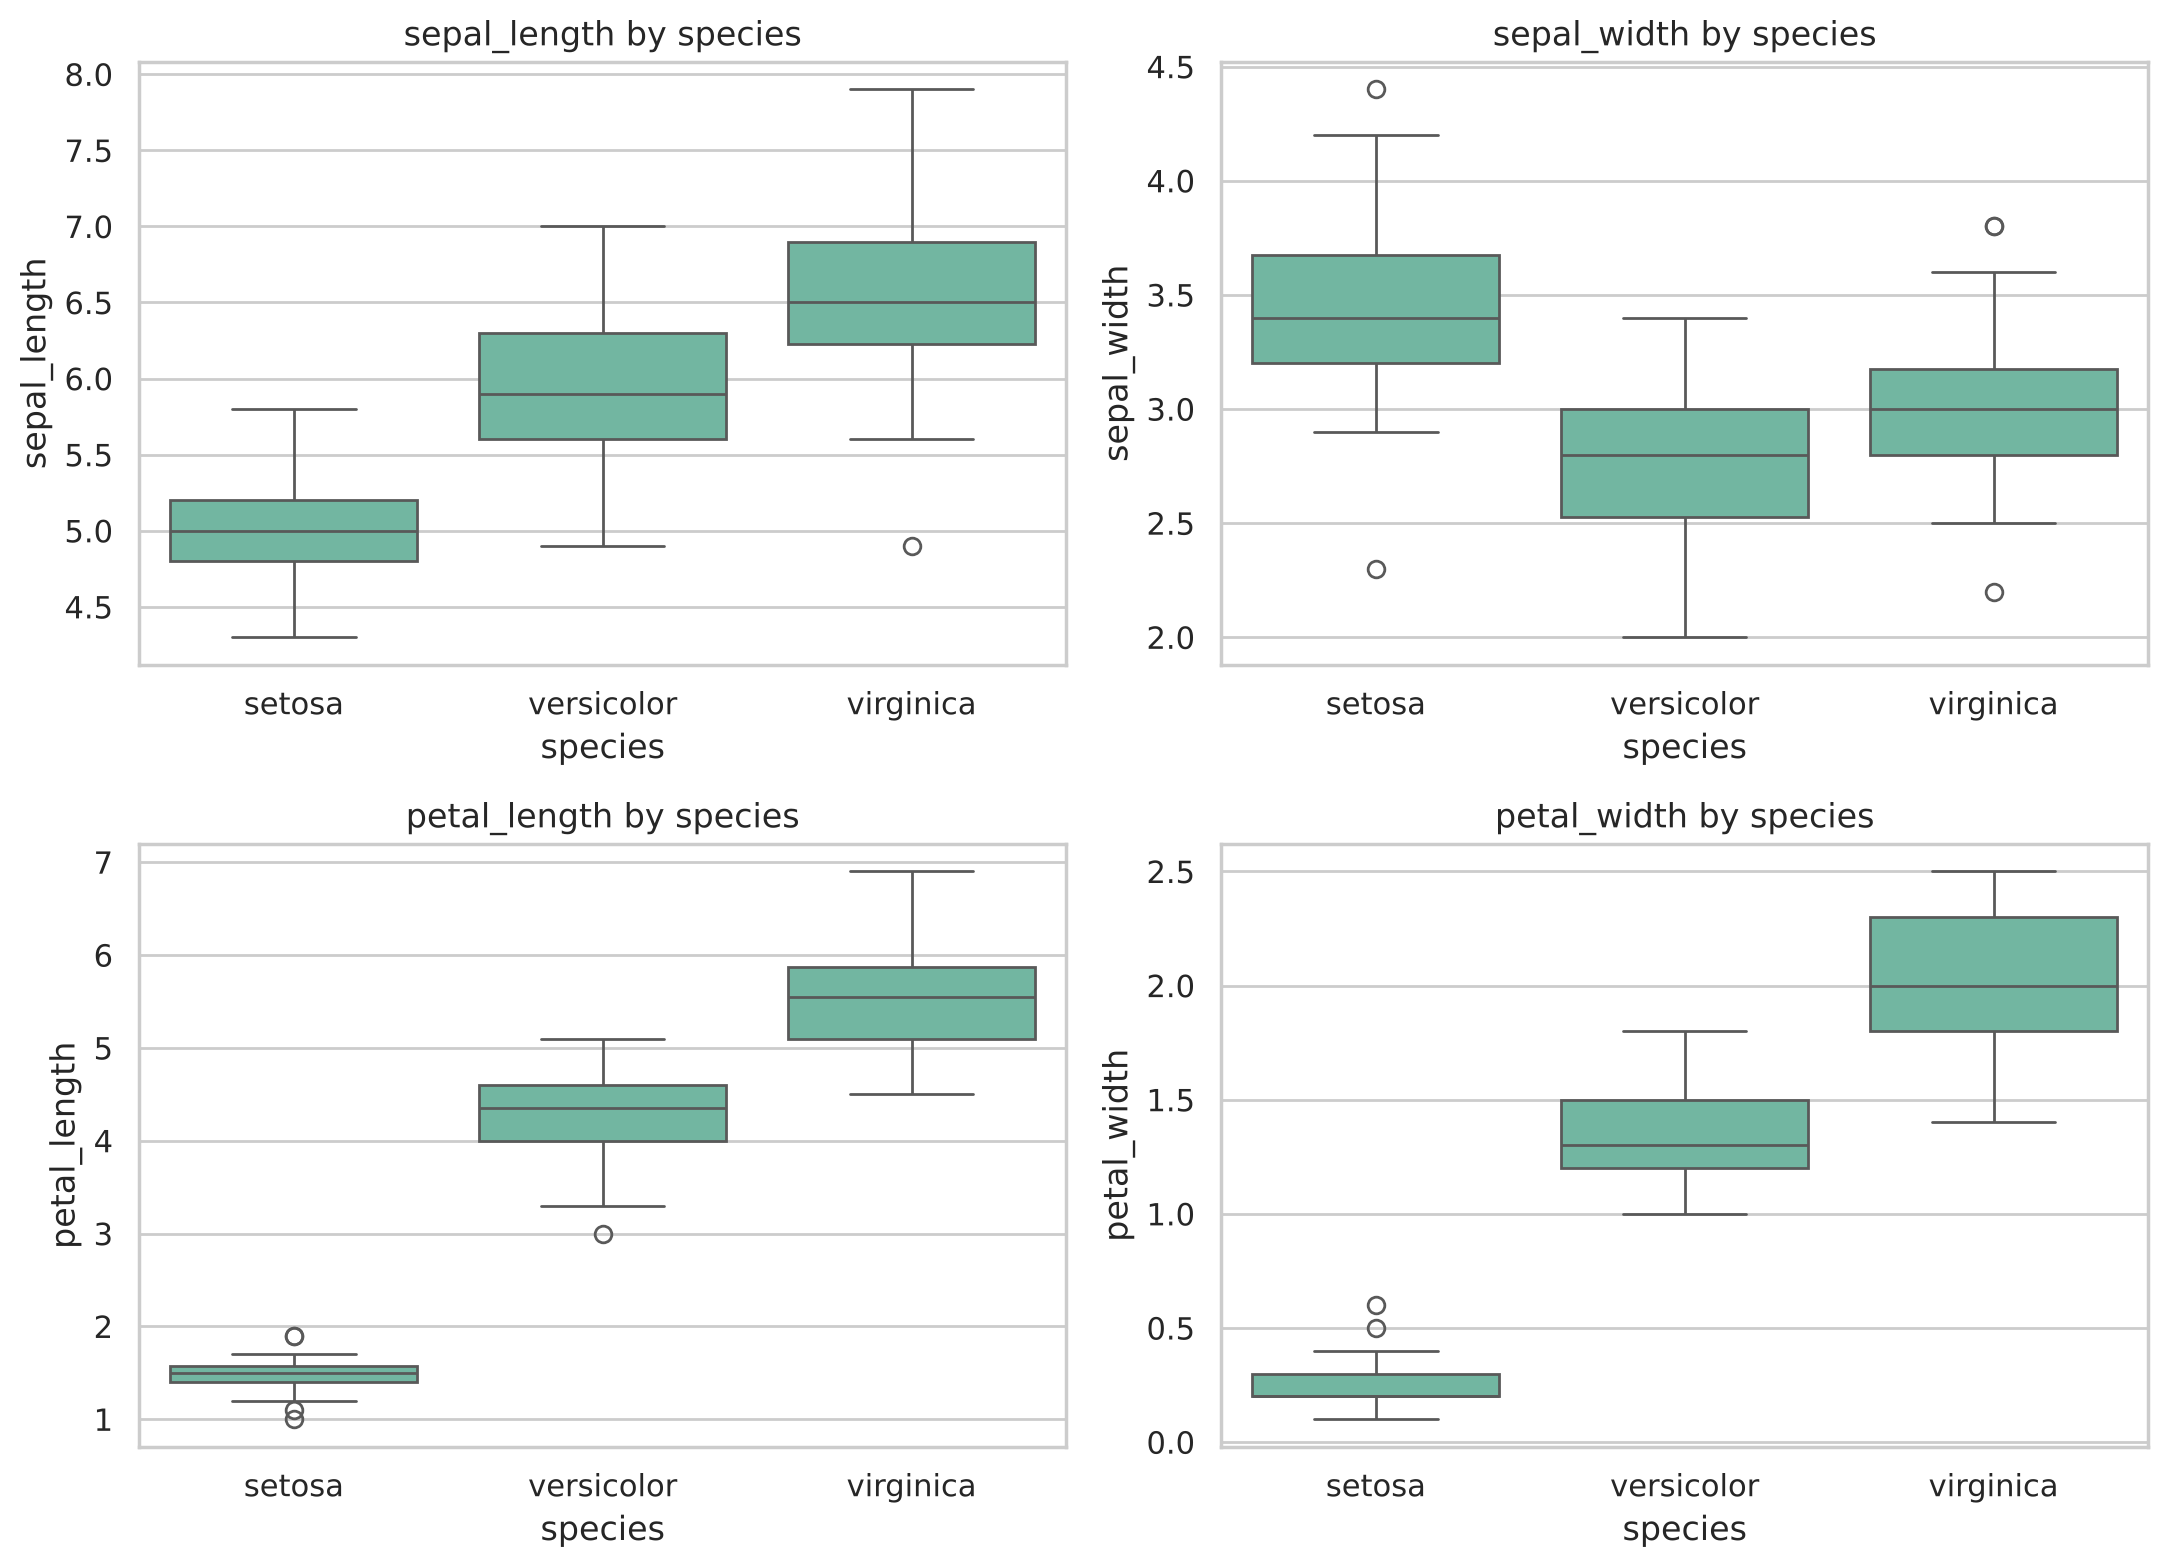

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feat, ax=ax)
    ax.set_title(f"{feat} by species")
plt.tight_layout()
plt.show()

**Observation:** The petal length and petal width box plots show almost no overlap between species, while sepal width overlaps heavily. A few outliers appear in sepal width, but there are very few and they are genuine measurements, so they are kept.

### 4.3 Correlation heatmap

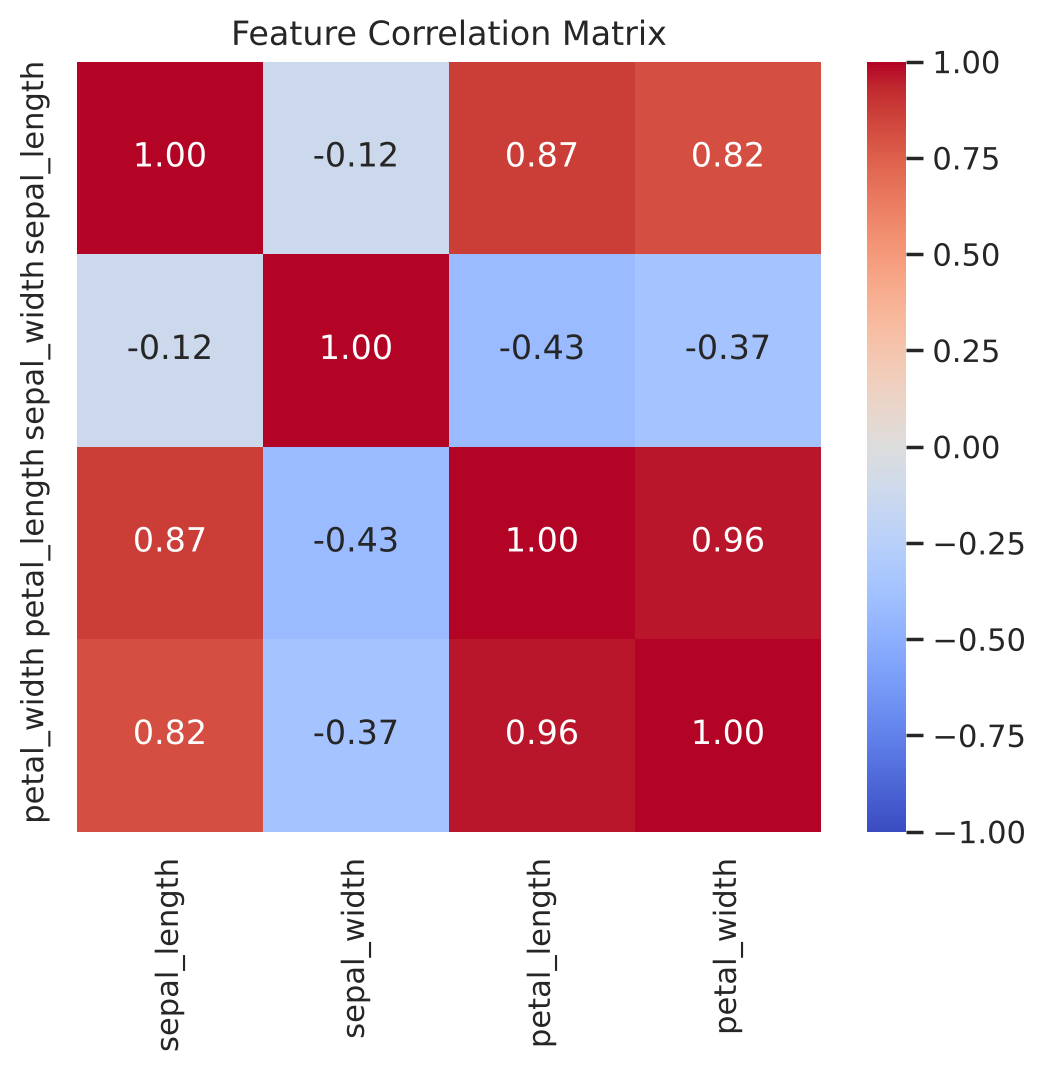

In [10]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.show()

## 5. Feature Selection Discussion
Which features are most discriminative?

- **Petal length and petal width** are the most discriminative. Their class means are far apart (Setosa about 1.5 cm / 0.2 cm petals vs Virginica about 5.6 cm / 2.0 cm), and the box plots barely overlap.
- **Sepal length** helps somewhat but overlaps between Versicolor and Virginica.
- **Sepal width** is the weakest feature: the three species overlap heavily.
- Petal length and petal width are also **highly correlated** (about 0.96), so they carry similar information. 

We still train on all four features because the dataset is tiny and the extra features cost nothing. We confirm the ranking later with the Random Forest feature importances.

## 6. Train/Test Split (80/20)
We use `stratify=y` so each species keeps the same proportion in both sets.

In [11]:
X = df.drop(columns="species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)
print("\nTest set class counts:")
print(y_test.value_counts())

Training set: (120, 4)
Test set    : (30, 4)

Test set class counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 7. Train the Models
We train four classifiers (the task requires at least two):
1. **Logistic Regression**: a linear baseline
2. **K-Nearest Neighbours (K=5)**: classifies by the majority class of the nearest points
3. **Decision Tree**: learns simple if/else rules
4. **Random Forest**: an ensemble of many decision trees

The measurements are all in centimetres on similar scales, so feature scaling is not needed here.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=RANDOM_STATE),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: K-Nearest Neighbours
Trained: Decision Tree
Trained: Random Forest


## 8. Evaluate Each Model
For every model we report the accuracy, confusion matrix and classification report (precision, recall, F1).

Logistic Regression  |  Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



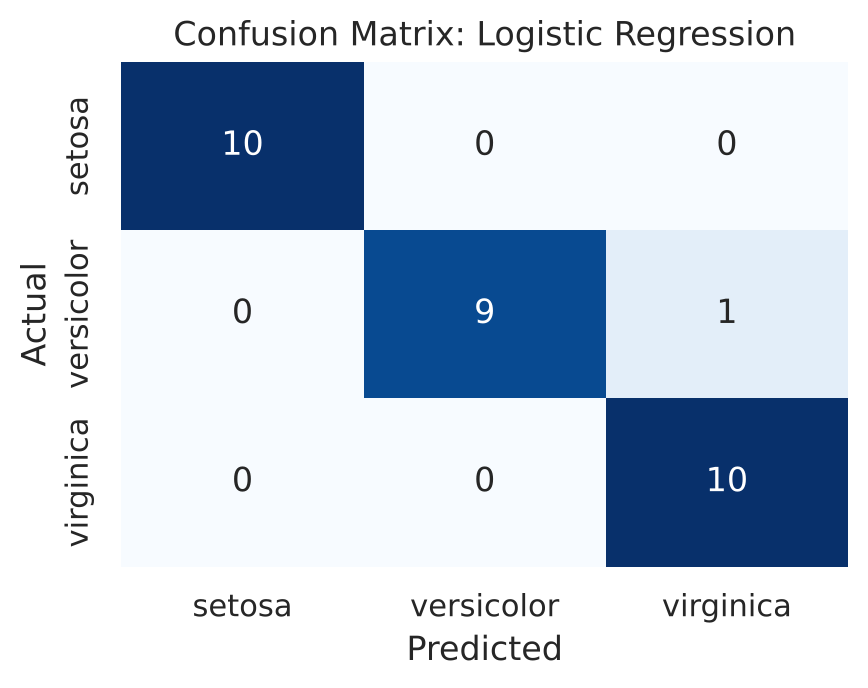

K-Nearest Neighbours  |  Accuracy: 1.0000
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



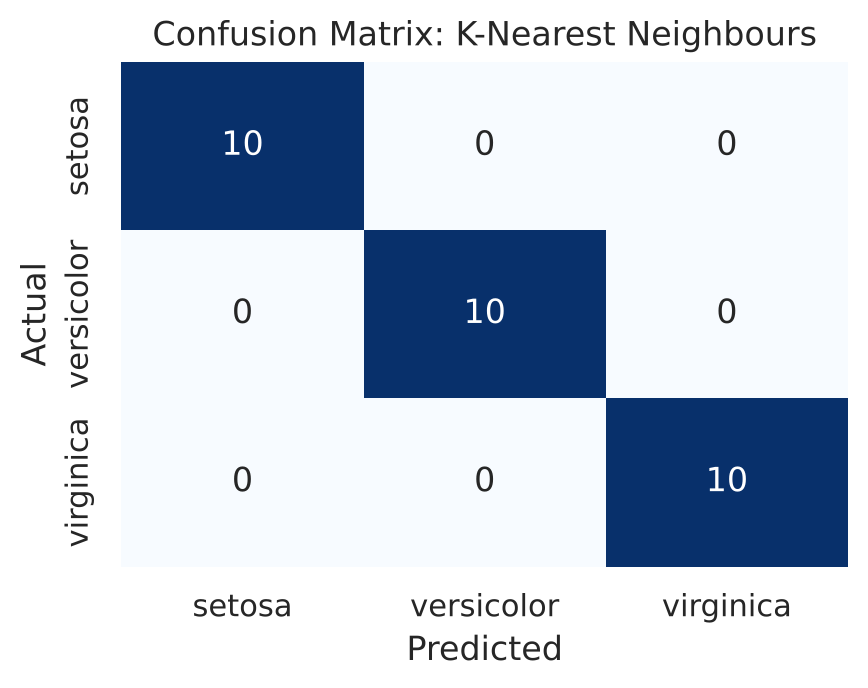

Decision Tree  |  Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



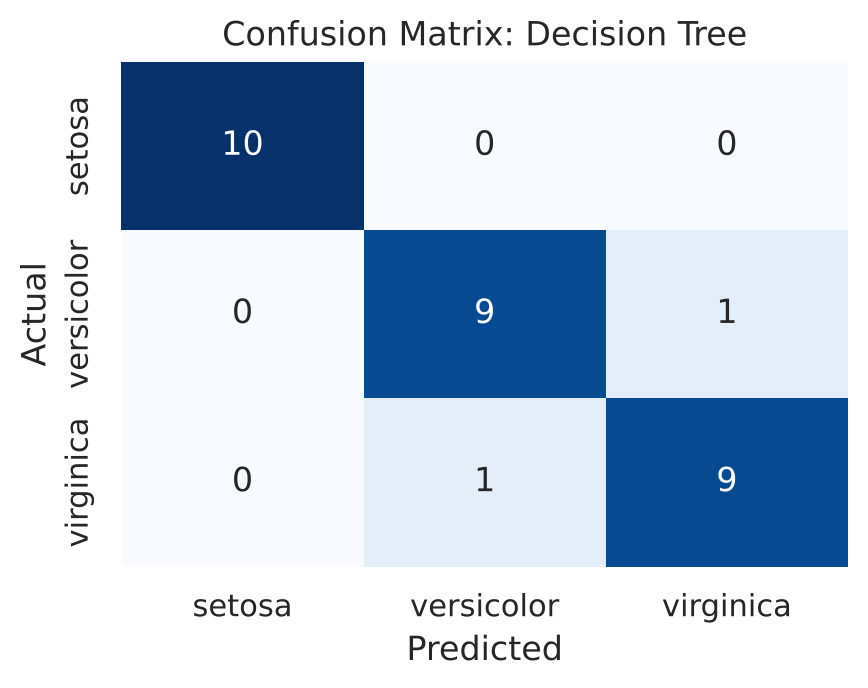

Random Forest  |  Accuracy: 0.9000
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.818     0.900     0.857        10
   virginica      0.889     0.800     0.842        10

    accuracy                          0.900        30
   macro avg      0.902     0.900     0.900        30
weighted avg      0.902     0.900     0.900        30



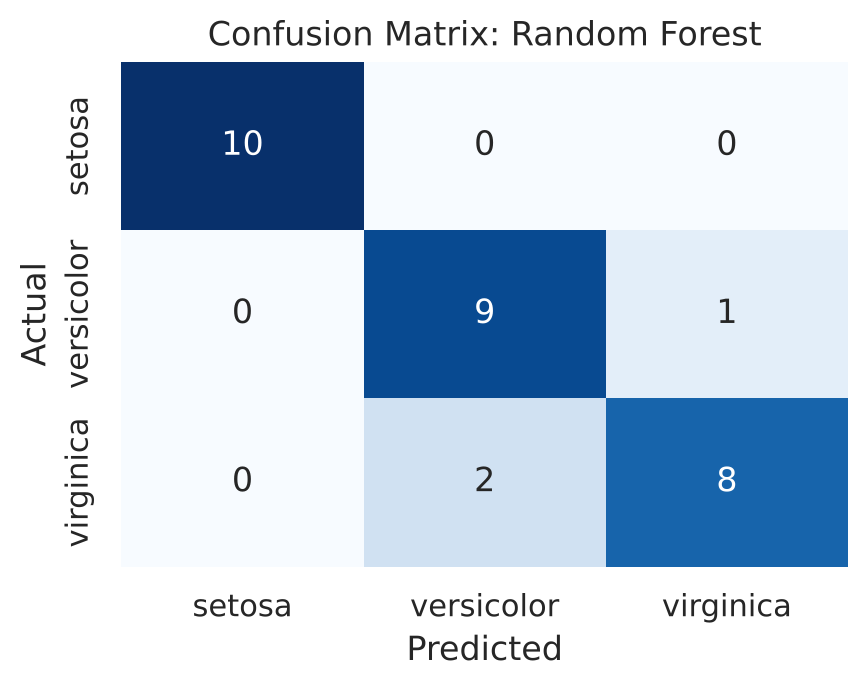

In [13]:
labels = list(iris.target_names)
results = []

for name, y_pred in predictions.items():
    acc = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": acc})

    print("=" * 60)
    print(f"{name}  |  Accuracy: {acc:.4f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=labels, digits=3))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(4.5, 3.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False)
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

### Model comparison

In [14]:
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df["Accuracy"] = results_df["Accuracy"].round(4)
results_df

,Model,Accuracy
0,K-Nearest Neighbours,1.0000
1,Logistic Regression,0.9667
2,Decision Tree,0.9333
3,Random Forest,0.9000


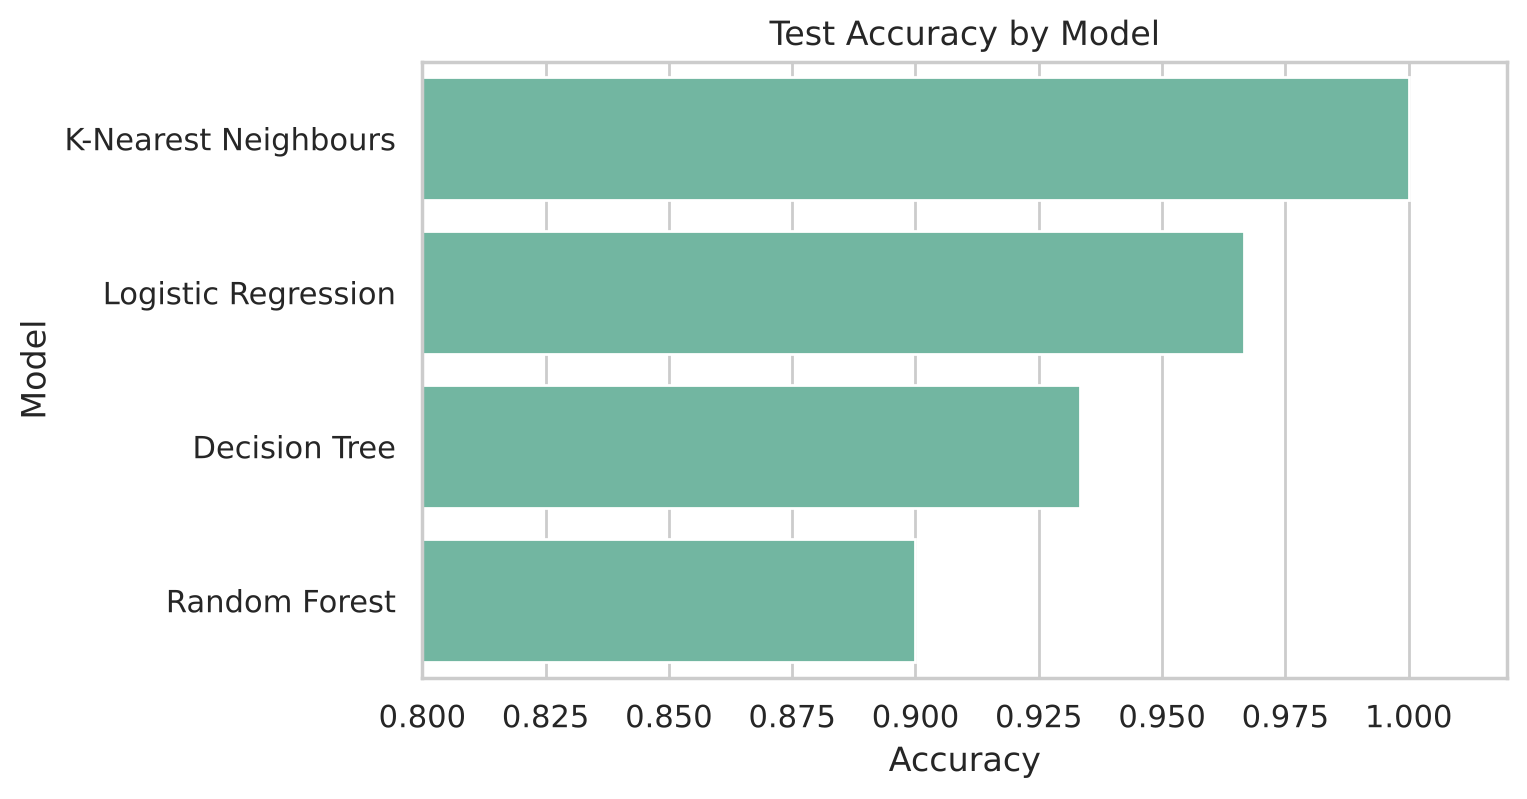

In [15]:
plt.figure(figsize=(7, 4))
sns.barplot(data=results_df, x="Accuracy", y="Model")
plt.xlim(0.8, 1.02)
plt.title("Test Accuracy by Model")
plt.show()

## 9. Feature Importance (Random Forest)
This confirms the feature discussion in Section 5.

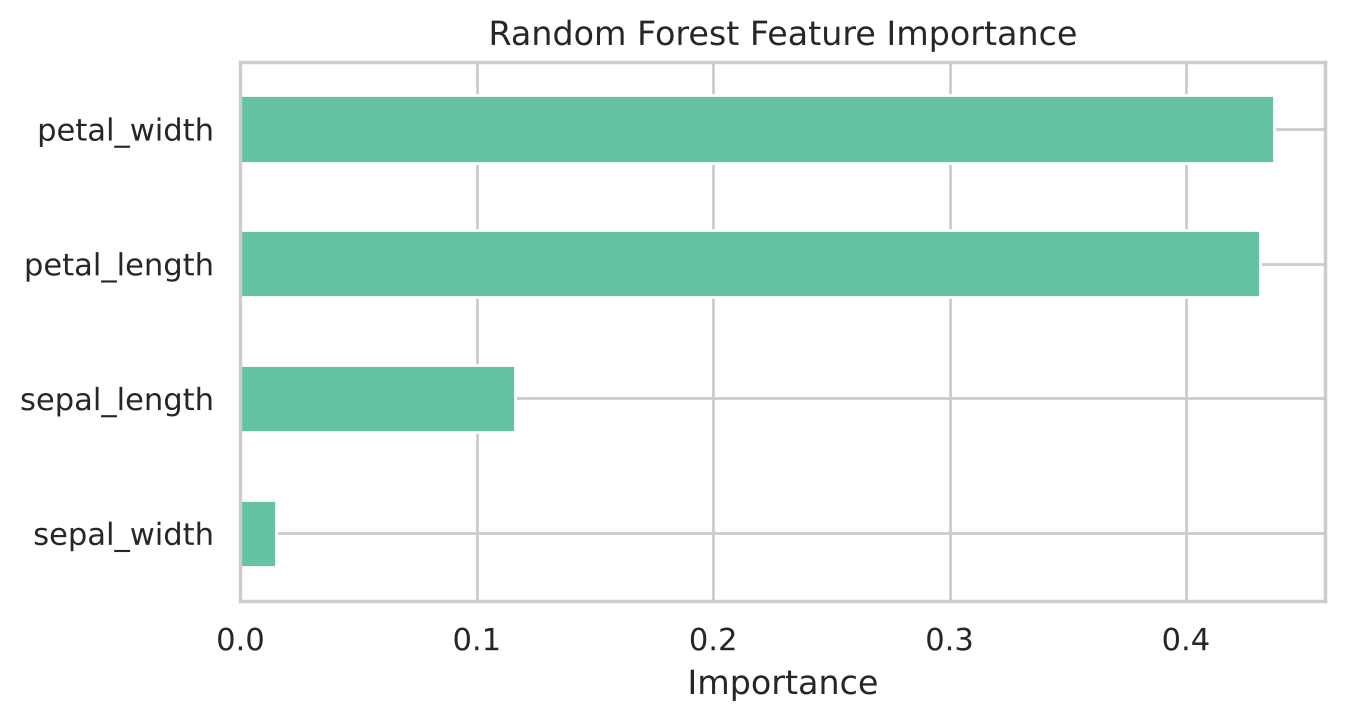

petal_width     0.437
petal_length    0.431
sepal_length    0.116
sepal_width     0.015
dtype: float64

In [16]:
importances = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(7, 3.5), title="Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()
importances.sort_values(ascending=False).round(3)

## 10. Cross-Validation (robustness check)
A single 30-sample test set is small, so one lucky or unlucky split can change the accuracy by several percent. 5-fold cross-validation gives a more reliable comparison.

In [17]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV Mean Accuracy": scores.mean(), "CV Std": scores.std()})

cv_df = pd.DataFrame(cv_rows).sort_values("CV Mean Accuracy", ascending=False).reset_index(drop=True)
cv_df.round(4)

,Model,CV Mean Accuracy,CV Std
0,Logistic Regression,0.9667,0.0298
1,K-Nearest Neighbours,0.9667,0.0298
2,Decision Tree,0.9533,0.0340
3,Random Forest,0.9467,0.0267


## 11. Best Model

In [18]:
best_test = results_df.iloc[0]
best_cv = cv_df.iloc[0]
print(f"Highest test accuracy : {best_test['Model']} ({best_test['Accuracy']:.4f})")
print(f"Highest CV accuracy   : {best_cv['Model']} ({best_cv['CV Mean Accuracy']:.4f} +/- {best_cv['CV Std']:.4f})")

Highest test accuracy : K-Nearest Neighbours (1.0000)
Highest CV accuracy   : Logistic Regression (0.9667 +/- 0.0298)


## 12. Conclusion
- The Iris dataset is clean, balanced (50 per class) and has no missing values.
- **Petal length and petal width** are the most discriminative features; *Setosa* is trivially separable, while *Versicolor* and *Virginica* overlap slightly.
- All four models reach 90% or higher on the test set. **K-Nearest Neighbours scored 100%** (30/30), followed by Logistic Regression (96.7%), Decision Tree (93.3%) and Random Forest (90.0%).
- Cross-validation tells a more reliable story: **Logistic Regression and KNN tie at about 96.7%**, Decision Tree reaches about 95.3% and Random Forest about 94.7%. The test-set ranking differs from the CV ranking because the 30-sample test set is so small.
- **Best model: K-Nearest Neighbours** (top test accuracy, tied for top CV accuracy). Logistic Regression is an equally good choice. The complex Random Forest gains nothing on such a simple, well-separated dataset, so the simpler models are preferred: they are faster and easier to explain.
- Random Forest feature importance confirms the earlier discussion: **petal width and petal length account for about 87% of importance**, and sepal width is almost irrelevant.
- **Limitation:** the dataset is small (150 samples), so the test set has only 30 rows and one misclassified flower moves accuracy by about 3.3%. That is why cross-validation was added.